# ¿Qué hace que un juego en Steam sea popular?

## 1. Introducción

### 1.1 Contexto

### 1.2 Objetivo

### 1.3 Variable Dependiente

### 1.4 Variable Independiente

### 1.5 Setup

In [2]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline # no es necesario

RANDOM_STATE = 2026
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. Base de Datos

### 2.1 Fuente

Martin Bustos Roman. (2022). Steam Games Dataset [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DS/2109585

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fronkongames/steam-games-dataset")
print("Path to dataset files:", path)

path_to_csv = os.path.join(path, "games.csv")
print("Path to csv file:", path_to_csv)

100%|██████████| 305M/305M [00:03<00:00, 96.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fronkongames/steam-games-dataset/versions/55
Path to csv file: /root/.cache/kagglehub/datasets/fronkongames/steam-games-dataset/versions/55/games.csv


### 2.2 Tamaño

In [4]:
# Loading the dataset and having a glimpse
raw_dataset = pd.read_csv(path_to_csv,
                   na_values="?",
                   comment='\t',
                   sep=','
                   )
print(f"Dimensions: {raw_dataset.shape}")

Dimensions: (125855, 39)


In [5]:
# Taking a look at the head of the dataset
raw_dataset.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DiscountDLC count,About the game,Supported languages,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.0000,0,0,NaN,[],...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.2400,65,0,"Springtime, April: when the cherry trees come ...",['English'],...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.9900,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.9900,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",['Korean'],...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.9900,0,0,Its not just a Maze; its a Quest! Enter the ca...,['English'],...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [6]:
# From a quick look and reading the discussion section in kaggle
# we notice there seems to be a comma missing between the header
# Discount, DLC count
# Applying the fix...
header = raw_dataset.columns.to_list()
print(f"Old Header: {header}")

fixed_header = header[:7] + ["Discount", "DLC count"] + header[8:]
fixed_dataset = pd.read_csv(path_to_csv,
                            na_values="?",
                            comment='\t',
                            sep=',',
                            names=fixed_header,
                            header=0
                            )
print(f"Fixed Dimensions: {fixed_dataset.shape}")
fixed_dataset.head()

Old Header: ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'DiscountDLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']
Fixed Dimensions: (125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.0000,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.2400,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.9900,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.9900,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.9900,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


### 2.3 Análisis

In [7]:
# Initial statistics of the data
fixed_dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
AppID,"125,855.0000","2,032,626.6052","1,117,434.0930",10.0000,"1,083,495.0000","1,949,010.0000","2,938,410.0000","4,437,540.0000"
Peak CCU,"125,855.0000",53.1872,"3,681.0830",0.0000,0.0000,0.0000,0.0000,"1,013,936.0000"
Required age,"125,855.0000",0.1654,1.6427,0.0000,0.0000,0.0000,0.0000,21.0000
Price,"125,855.0000",4.8112,12.4893,0.0000,0.5900,2.3900,5.5450,999.9800
Discount,"125,855.0000",17.8968,28.6285,0.0000,0.0000,0.0000,37.0000,100.0000
DLC count,"125,855.0000",0.5354,14.3284,0.0000,0.0000,0.0000,0.0000,"3,703.0000"
Metacritic score,"125,855.0000",2.5001,13.4929,0.0000,0.0000,0.0000,0.0000,97.0000
User score,"125,855.0000",0.0239,1.3768,0.0000,0.0000,0.0000,0.0000,100.0000
Positive,"125,855.0000","1,018.1821","27,727.8244",0.0000,0.0000,4.0000,35.0000,"7,642,084.0000"
Negative,"125,855.0000",164.8786,"5,305.0007",0.0000,0.0000,1.0000,10.0000,"1,173,003.0000"


falta texto, notar que es analisis de la base de datos, en general

### 2.4 Diccionario de Variables

Antes de empezar todo el analisis que viene a continuación, fue necesario corregir el header, pues dos variables venian unidas, pues le faltaba una coma.

Esto puede ser corroborado arriba.

- DiscountDLC count -> Discount, DLC discount

De esta manera tendríamos las 40 variables iniciales.

#### 2.4.1 Tipos de Dato

In [8]:
# Checking the data
fixed_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  object 
 2   Release date                125855 non-null  object 
 3   Estimated owners            125855 non-null  object 
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  object 
 10  Supported languages         125855 non-null  object 
 11  Full audio languages        125855 non-null  object 
 12  Reviews                     12181 non-null   object 
 13  Header image  

#### 2.4.2 Significado

significado de las variables...


## 3. Limpieza y Preparación

### 3.1 Suposiciones de Data

### 3.2 Modificaciones

Como fue mencionado desde el punto 2, como modificación inicial fue necesario corregir el headerd el dataset debido a una coma faltante entre Discount y DLC count.

#### 3.2.1 Missing Values

In [9]:
def missing_values_cleanup(dataset):
  new_dataset = dataset.copy()
  new_dataset = new_dataset.dropna()
  return new_dataset

# Checking for null values
print(fixed_dataset.isna().sum())

clean_dataset = missing_values_cleanup(fixed_dataset)

AppID                              0
Name                               1
Release date                       0
Estimated owners                   0
Peak CCU                           0
Required age                       0
Price                              0
Discount                           0
DLC count                          0
About the game                  8462
Supported languages                0
Full audio languages               0
Reviews                       113674
Header image                      81
Website                        75335
Support url                    70560
Support email                  22630
Windows                            0
Mac                                0
Linux                              0
Metacritic score                   0
Metacritic url                121597
User score                         0
Positive                           0
Negative                           0
Score rank                    125815
Achievements                       0
R

In [11]:
clean_dataset.shape

(0, 40)

In [12]:
clean_dataset.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies


## 4. Análisis Descriptivo y Correlación

### 4.1 Estadísticas Relevantes

### 4.2 Matriz de Correlación

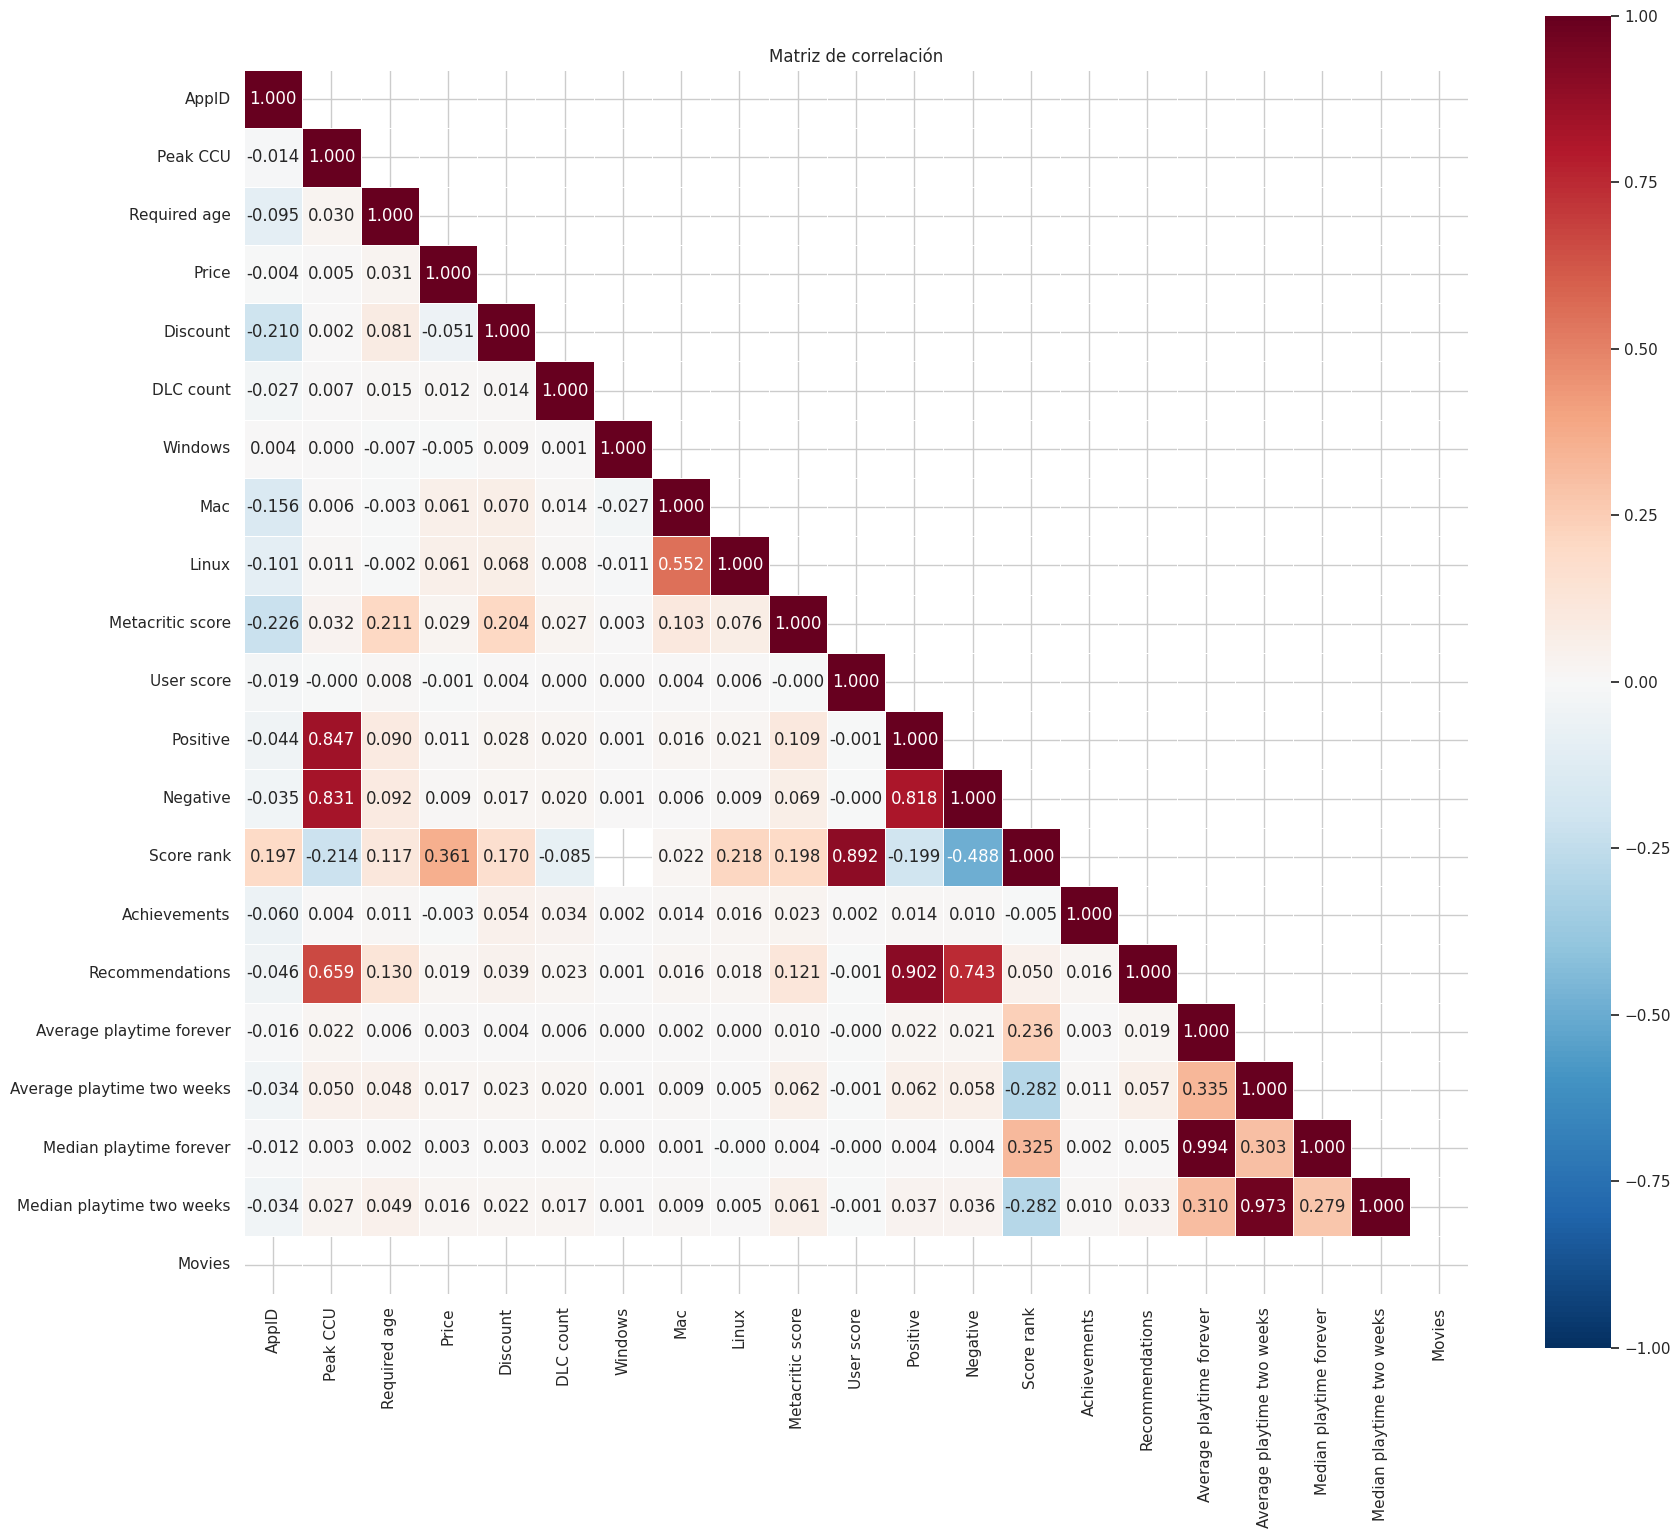

In [10]:
corr = fixed_dataset.corr(numeric_only=True)
plt.figure(figsize=(18, 18))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".3f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### 4.3 Interpretración

## 5. Selección de Variables

método completo fundamentado hasta el modelo final

## 6. Train/Test Split

análisis completo de los resultados del modelo final

## 7. Modelo Final (Regresión Lineal)

### 7.1 Ecuación Estimada

### 7.2 Interpretración de Coeficientes

## 8. Modelos Extra

Lasso, Ridge

No lineales:
- Random Forest
- Gradient Boosting
- Suport Vector Regression (SVR)

## 9. Conclusiones

### 9.1 Hallazgos

### 9.2 Limitaciones

### 9.3 Recomendaciones

### 9.4 Respuesta al Objetivo

## 10. Referencias

código (puede ser un link), tablas complementarias, etc.